In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [4]:
df = pd.read_csv("/Users/josegabriel/Desktop/ironhack/labs/lab-eda-univariate/amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [16]:
#Frequency Tables:
#Generate a frequency table for the product category.
#Which are the top 5 most listed product categories?
frequency_table = df['category'].value_counts()
#the top 5 are sports and outdoors, beauty, handmade clothing, shoes & acessories, bath & body and birthday gifs


uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

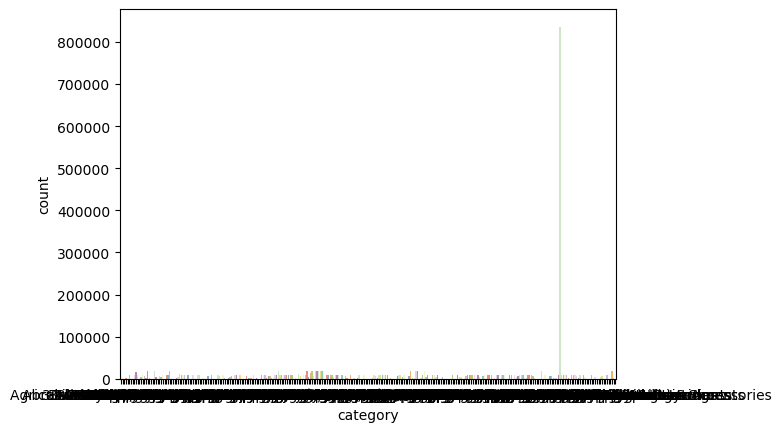

In [21]:
#Visualizations:
#Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
#For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?
my_table = pd.crosstab(index = df["category"],
                              columns="count")
my_table
sns.barplot(x=my_table.index, y=my_table['count'], palette='Set3')
plt.show()

<Axes: ylabel='count'>

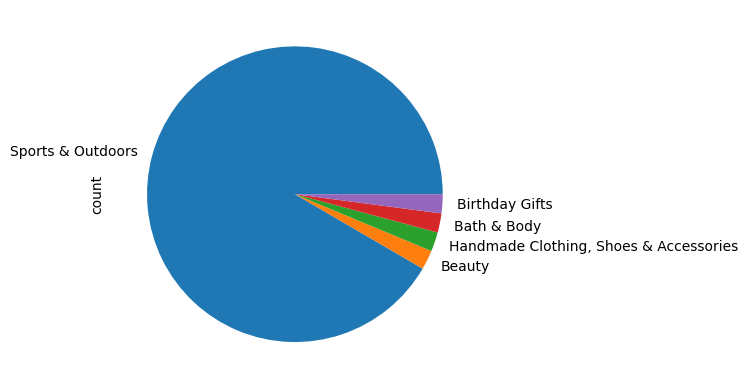

In [24]:
frequency_table.head(5).plot.pie()

In [25]:
#Measures of Centrality:
#Calculate the mean, median, and mode for the price of products.
#What's the average price point of products listed? How does this compare with the most common price point (mode)?
mean = df['price'].mean()
median = df['price'].median()
mode = df['price'].mode()[0]

mean, median, mode
#the average price is 89,2 dollars, but the most commomn price of the list is 9.99


(89.24380943923663, 19.09, 9.99)

In [26]:
#Measures of Dispersion:
#Determine the variance, standard deviation, range, and interquartile range for product price.
#How varied are the product prices? Are there any indicators of a significant spread in prices?

variance = df['price'].var()
std = df['price'].std()
range = (df['price'].max() - df['price'].min())
interquartile = df['price'].quantile([0.25, 0.5, 0.75])

variance, std, range, interquartile

(119445.4853225653,
 345.6088617535223,
 100000.0,
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='price', ylabel='Count'>

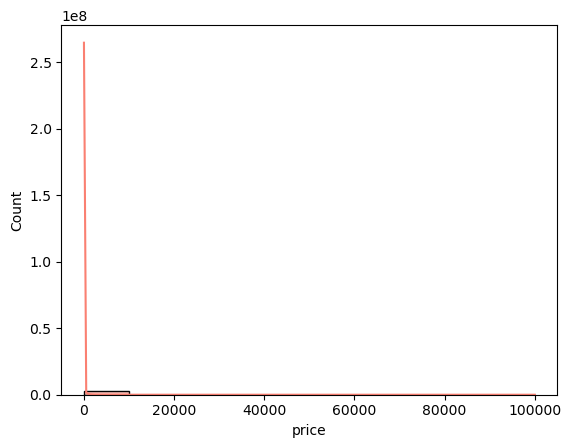

In [32]:
#Visualizations:
#Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. 
#If its hard to read these diagrams, think why this is, and explain how it could be solved..
#Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.
sns.histplot(df['price'], kde=True, bins=10, color="salmon")
#its hard to read because of the outlyers who made a very wide range and std
sns.boxplot(data = df['price'], color="lightblue")



<Axes: >

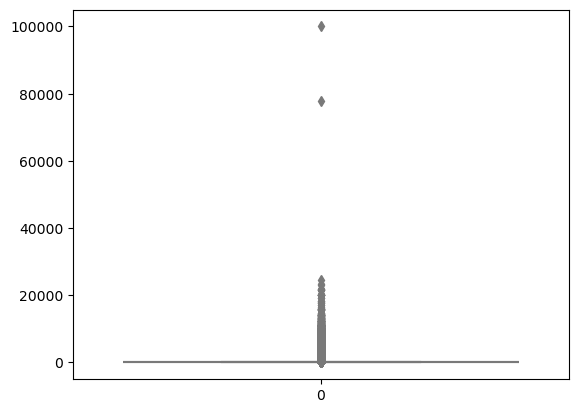

In [33]:
sns.boxplot(data = df['price'], color="lightblue")


In [37]:
#Measures of Centrality:
#Calculate the mean, median, and mode for the rating of products.
#How do customers generally rate products? Is there a common trend?
mean = df['stars'].mean()
median = df['stars'].median()
mode = df['stars'].mode()[0]
mean, median, mode
#the mean is 2.15 but the most common evalutation is 0

(2.152836472966065, 0.0, 0.0)

In [38]:
#Measures of Dispersion:
#Determine the variance, standard deviation, and interquartile range for product rating.
#Are the ratings consistent, or is there a wide variation in customer feedback?
variance = df['stars'].var()
std = df['stars'].std()
interquartile = df['stars'].quantile([0.25, 0.5, 0.75])

variance, std, interquartile
#we have a dispersed data from ratings, with a std of 2.19 and a a bigger amount of data in the 3rd quartile


(4.81743402976196,
 2.1948653785054697,
 0.25    0.0
 0.50    0.0
 0.75    4.4
 Name: stars, dtype: float64)

In [39]:
#Shape of the Distribution:
#Calculate the skewness and kurtosis for the rating column.
#Are the ratings normally distributed, or do they lean towards higher or lower values?

skewness_price = df['stars'].skew()
kurtosis_price = df['stars'].kurtosis()

skewness_price, kurtosis_price
#we have a distrubition of rating of right skewed.

(0.08120735761080985, -1.9260061280432985)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='stars', ylabel='Count'>

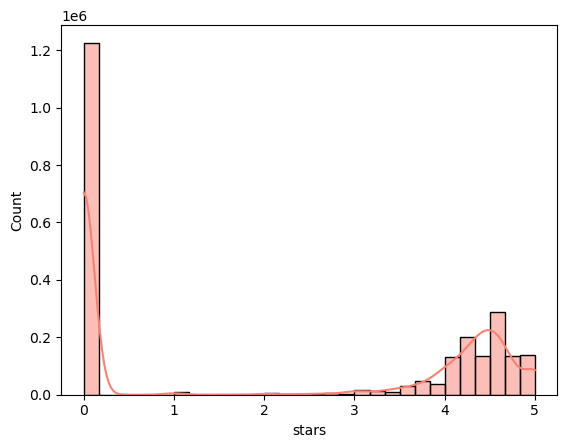

In [41]:
#Visualizations:
#Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
#the rating 0
sns.histplot(df['stars'], kde=True, bins=30, color="salmon")